# 01 — Exploring MovieLens 100K

Goal: understand the data before building any model.

In [2]:
import sys
sys.path.append("../src")

from recommender.data import load_ratings, load_movies, load_users

ratings = load_ratings()
movies = load_movies()
users = load_users()

## 1. How big is the data?

In [ ]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)

print(f"Users:   {n_users}")
print(f"Movies:  {n_movies}")
print(f"Ratings: {n_ratings}")

## 2. Is anything missing or duplicated?

In [ ]:
print("Missing values in ratings:", ratings.isna().sum().sum())
print("Same user rating the same movie twice:", ratings.duplicated(["user_id", "movie_id"]).sum())
print("Rating values:", sorted(ratings["rating"].unique().tolist()))

## 3. Sparsity

If every user had rated every movie there would be `n_users * n_movies` ratings. How many of those do we actually have?

In [ ]:
possible = n_users * n_movies
filled = n_ratings / possible

print(f"Possible ratings: {possible:,}")
print(f"Filled:           {filled:.2%}")
print(f"Empty (sparsity): {1 - filled:.2%}")

## 4. Rating distribution

How often is each star value given?

NameError: name 'n_ratings' is not defined

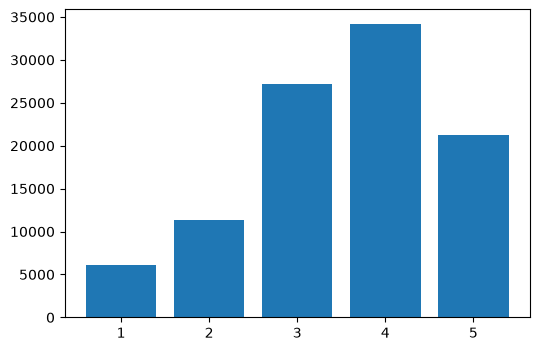

In [4]:
import matplotlib.pyplot as plt

counts = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values)
ax.bar_label(bars, labels=[f"{c / n_ratings:.1%}" for c in counts.values])
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of ratings")
ax.set_title("Distribution of ratings")
plt.show()

print(f"Mean rating:   {ratings['rating'].mean():.2f}")
print(f"Median rating: {ratings['rating'].median():.0f}")

In [5]:
movie_counts = ratings.groupby("movie_id").size().rename("n_ratings")

top = (
    movies[["movie_id", "title"]]
    .merge(movie_counts, on="movie_id")
    .sort_values("n_ratings", ascending=False)
)
top.head(10)

,movie_id,title,n_ratings
49,50,Star Wars (1977),583
257,258,Contact (1997),509
99,100,Fargo (1996),508
180,181,Return of the Jedi (1983),507
293,294,Liar Liar (1997),485
285,286,"English Patient, The (1996)",481
287,288,Scream (1996),478
0,1,Toy Story (1995),452
299,300,Air Force One (1997),431
120,121,Independence Day (ID4) (1996),429


In [7]:
print("Movies with only 1 rating:        ", (top["n_ratings"] == 1).sum())
print("Movies with fewer than 10 ratings:", (top["n_ratings"] < 10).sum())
print("Median ratings per movie:         ", top["n_ratings"].median())

top.tail(10)

Movies with only 1 rating:         141
Movies with fewer than 10 ratings: 530
Median ratings per movie:          27.0


,movie_id,title,n_ratings
1570,1571,Touki Bouki (Journey of the Hyena) (1973),1
1571,1572,Wend Kuuni (God's Gift) (1982),1
1348,1349,Mille bolle blu (1993),1
1573,1574,Pharaoh's Army (1995),1
1574,1575,"I, Worst of All (Yo, la peor de todas) (1990)",1
1575,1576,"Hungarian Fairy Tale, A (1987)",1
1576,1577,"Death in the Garden (Mort en ce jardin, La) (1...",1
1347,1348,Every Other Weekend (1990),1
1578,1579,Baton Rouge (1988),1
1681,1682,Scream of Stone (Schrei aus Stein) (1991),1


In [ ]:
user_counts = ratings.groupby("user_id").size()

print("Fewest ratings by one user:", user_counts.min())
print("Median ratings per user:   ", user_counts.median())
print("Average ratings per user:  ", round(user_counts.mean(), 1))
print("Most ratings by one user:  ", user_counts.max())

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(user_counts, bins=40)
ax.set_xlabel("Number of ratings given")
ax.set_ylabel("Number of users")
ax.set_title("Ratings per user")
plt.show()